# BANK CUSTOMER CHURN PREDICTION ANALYSIS

### Import Libraries | Import thư viện

In [1]:
import pandas as pd
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier


import shap
import warnings; warnings.filterwarnings('ignore')

d:\Đầu ra\BANK CUSTOMER CHURN\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Load data | Load dữ liệu

In [2]:
# Reading csv files
df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

In [3]:
# Checking info
print("\n ---TRAIN INFO---")
df_train.info()


 ---TRAIN INFO---
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               15000 non-null  int64  
 1   CustomerId       15000 non-null  float64
 2   Surname          15000 non-null  str    
 3   CreditScore      15000 non-null  float64
 4   Geography        15000 non-null  str    
 5   Gender           15000 non-null  str    
 6   Age              15000 non-null  float64
 7   Tenure           15000 non-null  float64
 8   Balance          15000 non-null  float64
 9   NumOfProducts    15000 non-null  float64
 10  HasCrCard        15000 non-null  float64
 11  IsActiveMember   15000 non-null  float64
 12  EstimatedSalary  15000 non-null  float64
 13  Exited           15000 non-null  float64
dtypes: float64(10), int64(1), str(3)
memory usage: 1.6 MB


In [4]:
# Checking info
print("\n ---TEST INFO---")
df_test.info()


 ---TEST INFO---
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               10000 non-null  int64  
 1   CustomerId       10000 non-null  float64
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  float64
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  float64
 7   Tenure           10000 non-null  float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  float64
 10  HasCrCard        10000 non-null  float64
 11  IsActiveMember   10000 non-null  float64
 12  EstimatedSalary  10000 non-null  float64
dtypes: float64(9), int64(1), str(3)
memory usage: 1015.8 KB


### Convert Datatypes

In [5]:
# Convert to integer columns for both training and testing sets | Chuyển thành các cột số nguyên cho cả 2 tập
int_columns = ["CreditScore", "Age", "Tenure", "NumOfProducts", "HasCrCard", "IsActiveMember"]
for col in int_columns:
    df_train[col] = df_train[col].astype('int64')
    df_test[col] = df_test[col].astype('int64')

# Convert the target variable (Exited) to integer column for training set | Chuyển cột Exited thành kiểu số nguyên cho tập train
df_train["Exited"] = df_train["Exited"].astype('int64')

# Convert to string columns for both training and testing sets | Chuyển thành dữ liệu dạng chuỗi cho cả 2 tập
str_columns = ["Geography", "Gender"]
for col in str_columns:
    df_train[col] = df_train[col].astype('object')
    df_test[col] = df_test[col].astype('object')

print("Successfully converted datatypes!")
print("\n ---Update Training Data Summary---")
df_train.info()

Successfully converted datatypes!

 ---Update Training Data Summary---
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               15000 non-null  int64  
 1   CustomerId       15000 non-null  float64
 2   Surname          15000 non-null  str    
 3   CreditScore      15000 non-null  int64  
 4   Geography        15000 non-null  object 
 5   Gender           15000 non-null  object 
 6   Age              15000 non-null  int64  
 7   Tenure           15000 non-null  int64  
 8   Balance          15000 non-null  float64
 9   NumOfProducts    15000 non-null  int64  
 10  HasCrCard        15000 non-null  int64  
 11  IsActiveMember   15000 non-null  int64  
 12  EstimatedSalary  15000 non-null  float64
 13  Exited           15000 non-null  int64  
dtypes: float64(3), int64(8), object(2), str(1)
memory usage: 1.6+ MB


### Exploratory Data Analysis (EDA) | Phân tích khám phá dữ liệu 
*(Train dataset)*

In [6]:
# Checking for missing values | Kiểm tra giá trị khuyết thiếu
print(df_train.isnull().sum())

id                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [7]:
# Checking for duplicated values | Kiểm tra giá trị trùng lặp
print(f"Duplicated values: {df_train.duplicated().sum()}")

Duplicated values: 0


Customer by Exited | Số lượng khách hàng từng nhóm:
Exited
0    11947
1     3053
Name: count, dtype: int64

Customer rate | Tỷ lệ phần trăm (%):
Exited
0    79.646667
1    20.353333
Name: proportion, dtype: float64


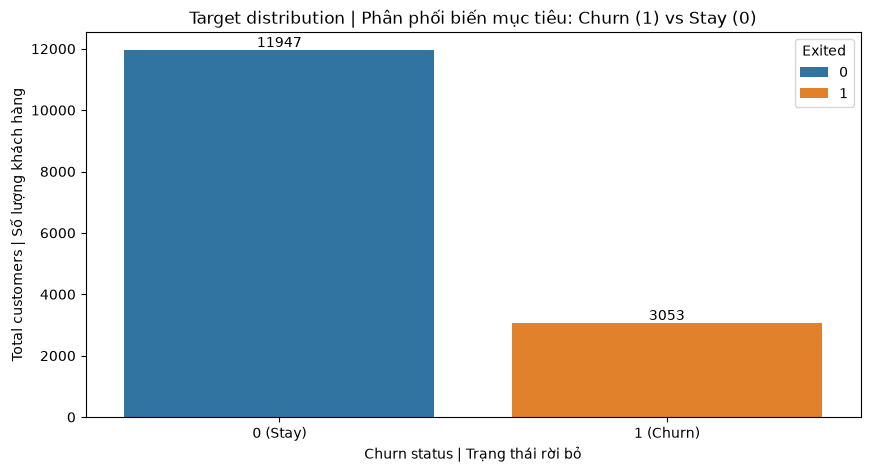

In [8]:
# Target distribution | Phân phối biến mục tiêu
target_counts = df_train["Exited"].value_counts()
target_percent = df_train["Exited"].value_counts(normalize = True) * 100
print(f"Customer by Exited | Số lượng khách hàng từng nhóm:\n{target_counts}")
print(f"\nCustomer rate | Tỷ lệ phần trăm (%):\n{target_percent}")

# Visualization | Trực quan hóa
plt.figure(figsize=(10, 5))
ax = sns.countplot(x='Exited', data=df_train, hue = "Exited")
ax.bar_label(ax.containers[0], fmt='%d')
ax.bar_label(ax.containers[1], fmt='%d')
plt.title('Target distribution | Phân phối biến mục tiêu: Churn (1) vs Stay (0)')
plt.xlabel('Churn status | Trạng thái rời bỏ')
plt.ylabel('Total customers | Số lượng khách hàng')
plt.xticks(ticks=[0, 1], labels=['0 (Stay)', '1 (Churn)'])
plt.show()

In [9]:
print("Data Describe | Mô tả dữ liệu")
df_train.describe()

Data Describe | Mô tả dữ liệu


,id,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,15000.000000,1.500000e+04,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,1.500000e+04,15000.000000
mean,7499.500000,1.569254e+07,658.549933,37.688333,5.039733,43365.350921,1.584733,0.780533,0.493000,1.197492e+05,0.203533
std,4330.271354,7.221883e+04,73.315114,8.132487,2.809558,59914.926512,0.527041,0.413899,0.499968,1.618335e+05,0.402639
min,0.000000,1.556490e+07,431.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,4.795400e+02,0.000000
25%,3749.750000,1.563247e+07,602.000000,32.000000,3.000000,0.000000,1.000000,1.000000,0.000000,8.347296e+04,0.000000
50%,7499.500000,1.569139e+07,661.000000,37.000000,5.000000,0.000000,2.000000,1.000000,0.000000,1.240456e+05,0.000000
75%,11249.250000,1.575805e+07,710.000000,42.000000,7.000000,109949.125000,2.000000,1.000000,1.000000,1.570971e+05,0.000000
max,14999.000000,1.581569e+07,850.000000,74.000000,30.000000,187841.990000,4.000000,1.000000,1.000000,1.817172e+07,1.000000


### Data preprocessing | Tiền xử lý dữ liệu

In [10]:
#  Extract and save "id" columns separately | Trích xuất và lưu riêng cột "id" 
train_ids = df_train["id"]
test_ids = df_test["id"]
print(train_ids, test_ids)

0            0
1            1
2            2
3            3
4            4
         ...  
14995    14995
14996    14996
14997    14997
14998    14998
14999    14999
Name: id, Length: 15000, dtype: int64 0       15000
1       15001
2       15002
3       15003
4       15004
        ...  
9995    24995
9996    24996
9997    24997
9998    24998
9999    24999
Name: id, Length: 10000, dtype: int64


In [11]:
# Drop non-predictive columns | Drop các cột không dùng để dự đoán
cols_to_drop = ["id", "CustomerId", "Surname" ]
df_train = df_train.drop(columns = cols_to_drop, errors = "ignore")
df_test = df_test.drop(columns = cols_to_drop, errors = "ignore")
print("Successfully removed non-predictive columns!")

Successfully removed non-predictive columns!


In [12]:
print(df_train.shape)
print(f"Các cột cần thiết: {df_train.columns}")
print("---Training Data---")
df_train.head(5)

(15000, 11)
Các cột cần thiết: Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited'],
      dtype='str')
---Training Data---


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,675,France,Female,37,5,0.00,1,1,0,131778.57,1
1,599,France,Male,28,8,0.00,1,1,0,81299.09,0
2,706,Germany,Female,40,9,155619.58,1,1,1,81622.08,1
3,705,Germany,Male,42,3,81231.85,2,1,0,134720.51,0
4,597,France,Male,49,9,0.00,1,1,0,151844.81,1


In [13]:
print("---Testing Data---")
df_test.head(5)

---Testing Data---


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,649,Germany,Male,37,3,106534.40,1,1,1,131173.90
1,717,France,Female,41,2,0.00,2,1,1,93767.03
2,850,France,Male,45,4,0.00,1,1,0,132424.69
3,593,France,Male,43,8,0.00,2,1,0,43921.22
4,682,Germany,Female,35,3,118097.87,2,0,0,123982.14


*One-hot encoding & Scaler*

In [14]:
# Split the training dataset into features (X) and target (y)
# Chia tập train thành biến X và biến mục tiêu y
X = df_train.drop(columns = ["Exited"])
y = df_train["Exited"]
# Chia 80% để train, 20% để test/validation nội bộ trên tập train
# stratify=y giúp giữ nguyên tỷ lệ rời bỏ ~20% ở cả 2 tập
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, 
    random_state=42, 
    stratify=y
)
# Lấy tập test
X_test = df_test

In [32]:
# One-hot encoding | Mã hóa biến phân loại
# Khởi tạo bộ mã hóa (handle_unknown='ignore' giúp xử lý nếu tập Test xuất hiện nhãn lạ)
encoder = OneHotEncoder(sparse_output=False)

# Chọn các cột dạng chữ cần mã hóa
categorical_cols = ['Geography', 'Gender']

# Fit trên Train, Transform trên Validation và Test
train_encoded = encoder.fit_transform(X_train[categorical_cols])
val_encoded   = encoder.transform(X_val[categorical_cols])
test_encoded  = encoder.transform(X_test[categorical_cols])  # Thêm tập Test

# Lấy tên cột mới sau khi drop first
encoded_cols = encoder.get_feature_names_out(categorical_cols)

# Tạo DataFrame và bắt buộc giữ nguyên index gốc để ghép nối không bị khuyết thiếu do train_test_split
df_train_encoded = pd.DataFrame(train_encoded, columns=encoded_cols, index=X_train.index)
df_val_encoded   = pd.DataFrame(val_encoded,   columns=encoded_cols, index=X_val.index)
df_test_encoded  = pd.DataFrame(test_encoded,  columns=encoded_cols, index=X_test.index)

print(f"Shape Train Encoded: {df_train_encoded.shape}")
print(f"Shape Val Encoded:   {df_val_encoded.shape}")
print(f"Shape Test Encoded:  {df_test_encoded.shape}")

Shape Train Encoded: (12000, 5)
Shape Val Encoded:   (3000, 5)
Shape Test Encoded:  (10000, 5)


In [33]:
# StandardScaler | Chuẩn hóa dữ liệu
numeric_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
scaler = StandardScaler()

# Fit scaler trên X_train và X_val của tập train
train_scaler = scaler.fit_transform(X_train[numeric_cols])
val_scaler = scaler.transform(X_val[numeric_cols])
test_scaler = scaler.transform(X_test[numeric_cols])

# Chuyển kết quả về dạng DataFrame để ghép lại vào dữ liệu gốc
scaler_cols = scaler.get_feature_names_out(numeric_cols)
df_train_scaler = pd.DataFrame(train_scaler, columns=scaler_cols, index=X_train.index)
df_val_scaler = pd.DataFrame(val_scaler, columns=scaler_cols, index=X_val.index)
df_test_scaler  = pd.DataFrame(test_scaler,  columns=scaler_cols, index=X_test.index)

print(f"Shape Train Scaler: {df_train_scaler.shape}")
print(f"Shape Val Scaler:   {df_val_scaler.shape}")
print(f"Shape Test Scaler:  {df_test_scaler.shape}")


Shape Train Scaler: (12000, 6)
Shape Val Scaler:   (3000, 6)
Shape Test Scaler:  (10000, 6)


In [34]:
# Ghép toàn bộ lại thành bảng hoàn chỉnh
passthrough_cols = ['HasCrCard', 'IsActiveMember']

X_train_final = pd.concat([df_train_scaler, df_train_encoded, X_train[passthrough_cols]], axis=1)
X_val_final   = pd.concat([df_val_scaler,   df_val_encoded,   X_val[passthrough_cols]],   axis=1)
X_test_final  = pd.concat([df_test_scaler,  df_test_encoded,  X_test[passthrough_cols]],  axis=1)

# Reset index để tránh sinh ra giá trị NaN
X_train_final = X_train_final.reset_index(drop=True)
X_val_final = X_val_final.reset_index(drop=True)
X_test_final  = X_test_final.reset_index(drop=True)

print("\nKích thước tập Train cuối cùng:", X_train_final.shape)
print("Kích thước tập Val cuối cùng:  ", X_val_final.shape)
print("Kích thước tập Test cuối cùng: ", X_test_final.shape)


Kích thước tập Train cuối cùng: (12000, 13)
Kích thước tập Val cuối cùng:   (3000, 13)
Kích thước tập Test cuối cùng:  (10000, 13)


### Correlation Matrix | Ma trận tương quan

Mức độ tương quan với nhãn rời bỏ:
Age                  0.447388
Geography_Germany    0.236017
Gender_Female        0.168218
Balance              0.139780
EstimatedSalary      0.009209
HasCrCard            0.002321
Tenure              -0.030268
CreditScore         -0.040527
Geography_Spain     -0.044775
Geography_France    -0.149788
Gender_Male         -0.168218
IsActiveMember      -0.202163
NumOfProducts       -0.300824
Name: Exited, dtype: float64


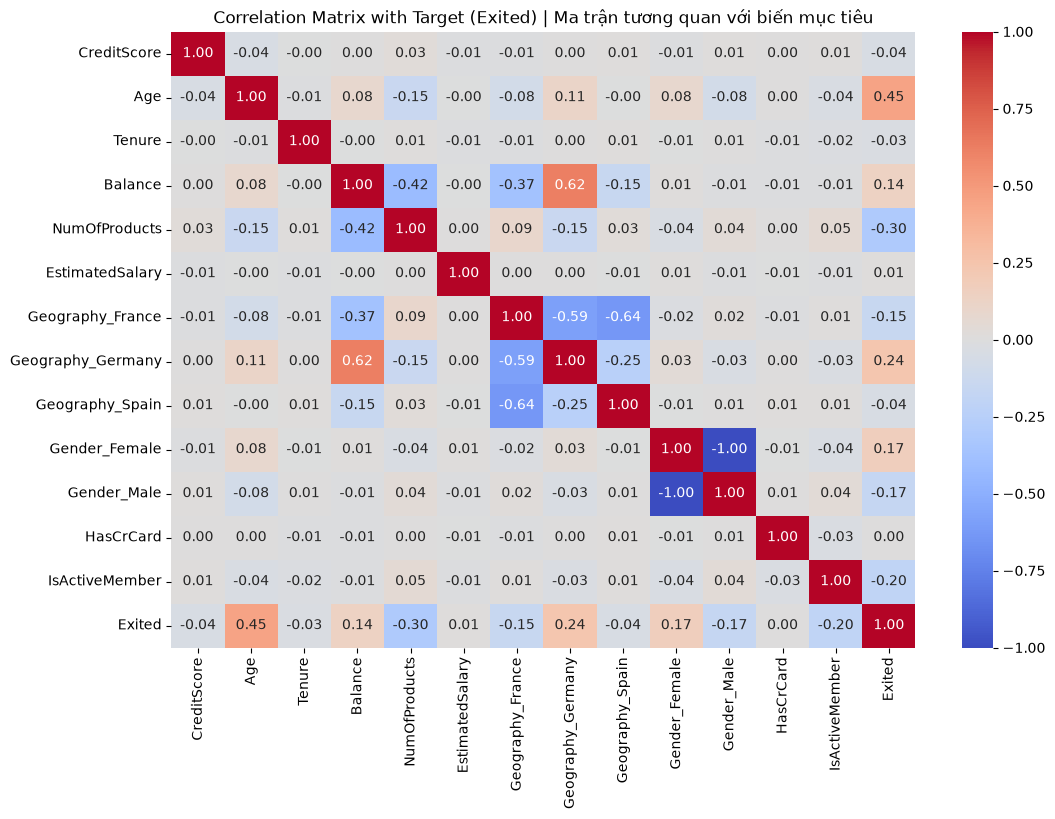

In [35]:
# Tạo bảng tạm gồm cả X_train và y_train
train_with_target = X_train_final.copy()
train_with_target['Exited'] = y_train.values
corr_matrix = train_with_target.corr()

# Xem mức độ tương quan của từng yếu tố với hành vi rời bỏ (Exited)
target_corr = corr_matrix['Exited'].drop('Exited').sort_values(ascending=False)
print("Mức độ tương quan với nhãn rời bỏ:")
print(target_corr)

# Visualization | Trực quan hóa
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation Matrix with Target (Exited) | Ma trận tương quan với biến mục tiêu")
plt.show()

### Class weights | Tính trọng số mô hình

In [36]:
# Tính trọng số lớp dựa trên y_train
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(zip(np.unique(y_train), class_weights))

print("Class weights:", class_weights)

Class weights: {np.int64(0): np.float64(0.6277463904582549), np.int64(1): np.float64(2.457002457002457)}


### Model training & Evaluation | Huấn luyện mô hình và đánh giá

**Khởi tạo mô hình**
* Logistic Regression
* Random Forest
* LightGBM
* XGBoost

In [37]:
# Tính tỷ lệ số khách ở lại (0) chia cho số khách rời bỏ (1) để phạt XGBoost
scale_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()

# Khởi tạo từng mô hình vào một dictionary
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(max_depth=10, class_weight='balanced', random_state=42),
    'LightGBM': LGBMClassifier(max_depth=5, learning_rate=0.05, class_weight='balanced', random_state=42),
    'XGBoost': XGBClassifier(max_depth=5, learning_rate=0.05, scale_pos_weight=scale_pos_ratio, random_state=42)
}

print("Đã khởi tạo xong 4 mô hình!")

Đã khởi tạo xong 4 mô hình!


- *scale_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum(): Đếm xem lớp đa số (0) gấp bao nhiêu lần lớp thiểu số (1)*
- *class_weight='balanced': Dùng cho Logistic Regression, Random Forest và LightGBM. Nó tự động nhân hệ số phạt để mô hình không bỏ sót khách hàng rời bỏ.*
- *scale_pos_weight=scale_pos_ratio: Riêng XGBoost không có tham số class_weight, nên phải truyền trực tiếp tỷ lệ vừa tính vào đây.*
- *random_state=42: Cố định hạt giống ngẫu nhiên để mỗi lần bạn chạy lại code thì kết quả luôn đồng nhất.*

**Huấn luyện và dự đoán xác suất trên tập Validation**

In [38]:
# Tạo 3 dictionary rỗng để lưu trữ kết quả sau khi chạy
trained_models = {}   # Lưu mô hình đã học
probas_val = {}       # Lưu xác suất rời bỏ (từ 0.0 đến 1.0)
preds_val_05 = {}     # Lưu nhãn dự đoán 0 hoặc 1 (theo ngưỡng 0.5)

for name, model in models.items():
    print(f"Đang huấn luyện {name}...")
    
    # Cho mô hình học trên tập Train
    model.fit(X_train_final, y_train)
    trained_models[name] = model
    
    # Dự đoán xác suất khách hàng rời bỏ (cột số 1)
    y_proba = model.predict_proba(X_val_final)[:, 1]
    probas_val[name] = y_proba
    
    # So sánh xác suất với ngưỡng 0.5: nếu >= 0.5 thì đoán là 1 (rời bỏ), ngược lại là 0
    y_pred = (y_proba >= 0.5).astype(int)
    preds_val_05[name] = y_pred

print("Đã hoàn thành huấn luyện và dự đoán cho cả 4 mô hình!")

Đang huấn luyện Logistic Regression...
Đang huấn luyện Random Forest...
Đang huấn luyện LightGBM...
[LightGBM] [Info] Number of positive: 2442, number of negative: 9558
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000100 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 846
[LightGBM] [Info] Number of data points in the train set: 12000, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with p

- *model.fit(X_train_final, y_train): Lệnh thực hiện việc huấn luyện. Mô hình đối chiếu 11 cột đặc trưng với nhãn Exited để tìm quy luật.*
- *model.predict_proba(X_val_final)[:, 1]: Hàm trả về xác suất của 2 lớp: [:, 0] là xác suất ở lại, [:, 1] là xác suất rời bỏ. Ta chỉ quan tâm đến nguy cơ rời bỏ nên lấy cột số 1.*
- *(y_proba >= 0.5).astype(int): Phân loại theo ngưỡng mặc định. Nếu xác suất >= 0.5, chuyển thành 1 (Rời bỏ); nếu < 0.5, chuyển thành 0 (Ở lại).*

**Tính toán các chỉ số** & **Vẽ ma trận nhầm lẫn (Confusion Matrix)**
* Accuracy
* Precision
* Recall
* F1-score
* ROC-AUC


BẢNG ĐÁNH GIÁ 4 MÔ HÌNH (NGƯỠNG MẶC ĐỊNH 0.5):


,Model,Số mẫu Validation,Accuracy,Precision,Recall,F1-Score,AUC-ROC
2,LightGBM,3000,0.8703,0.6384,0.8380,0.7247,0.9361
3,XGBoost,3000,0.8690,0.6356,0.8363,0.7223,0.9351
1,Random Forest,3000,0.8740,0.6511,0.8216,0.7265,0.9309
0,Logistic Regression,3000,0.8280,0.5540,0.7971,0.6537,0.8867


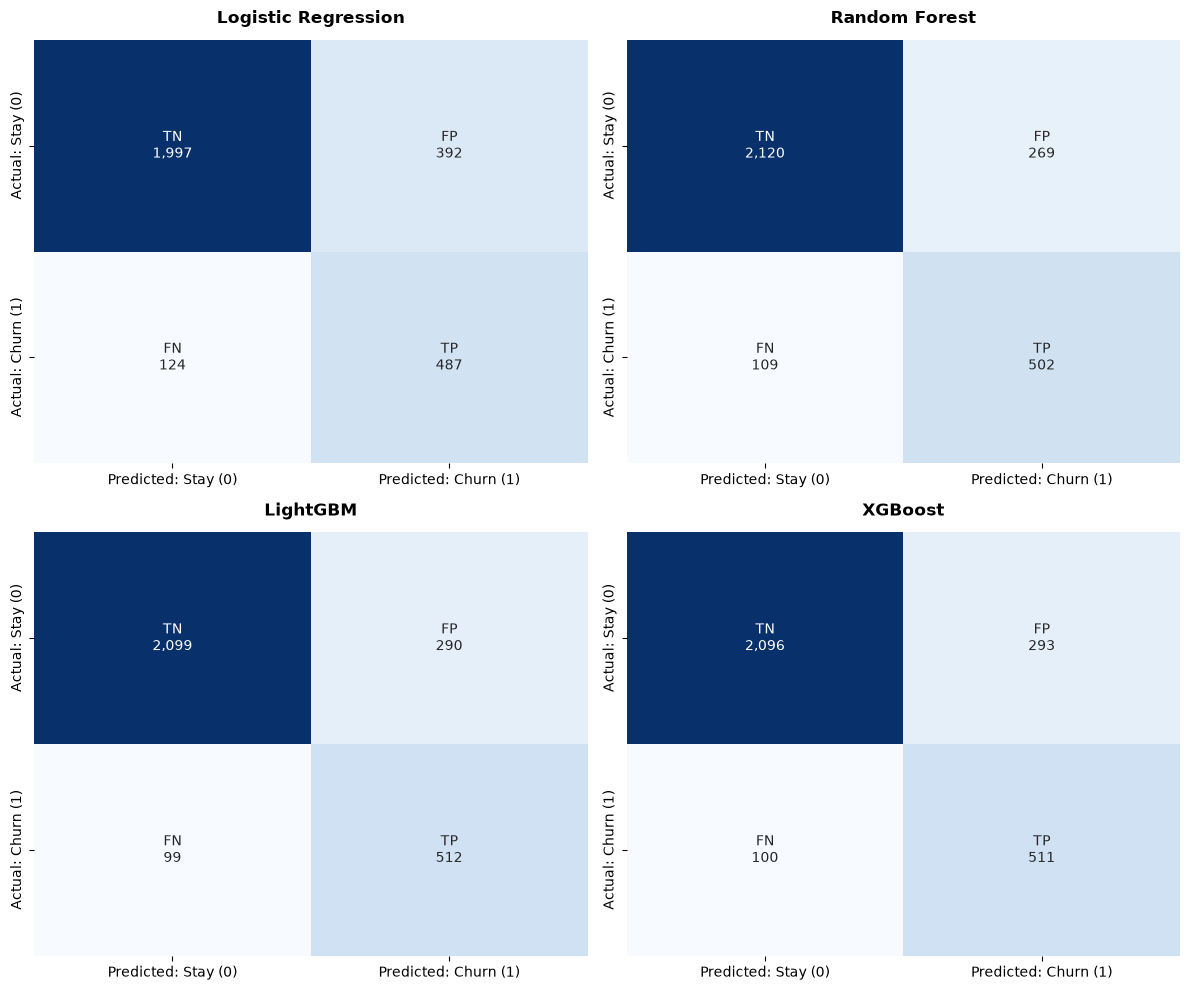

In [39]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

results_05 = []

for name in models.keys():
    # Lấy nhãn dự đoán và xác suất đã lưu ra chấm điểm
    pred = preds_val_05[name]
    proba = probas_val[name]
    
    # Tính từng chỉ số
    acc = accuracy_score(y_val, pred)
    prec = precision_score(y_val, pred, zero_division=0)
    rec = recall_score(y_val, pred)
    f1 = f1_score(y_val, pred)
    auc = roc_auc_score(y_val, proba)
    
    # Gom vào danh sách kết quả
    results_05.append({
        'Model': name,
        'Số mẫu Validation': len(y_val),
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'AUC-ROC': round(auc, 4)
    })

# Đưa vào DataFrame và sắp xếp ưu tiên mô hình có AUC-ROC cao nhất lên đầu
df_results_05 = pd.DataFrame(results_05).sort_values(by='AUC-ROC', ascending=False)

print("BẢNG ĐÁNH GIÁ 4 MÔ HÌNH (NGƯỠNG MẶC ĐỊNH 0.5):")
display(df_results_05)

# Confusion Matrix
# Tạo lưới 2 hàng x 2 cột cho 4 mô hình
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))
axes_list = axes.ravel()

# Định nghĩa từng ô
cell_meanings = ["TN","FP","FN","TP"]

for idx, (name, pred) in enumerate(preds_val_05.items()):
    # Tính số lượng từng ô
    cm = confusion_matrix(y_val, pred)

    # Nhãn theo cm của từng mô hình
    formatted_labels = [
        f"{meaning}\n{count:,}" 
        for meaning, count in zip(cell_meanings, cm.flatten())
    ]
    formatted_labels = np.array(formatted_labels).reshape(2, 2)
    
    # Vẽ heatmap
    sns.heatmap(
        cm, 
        annot=formatted_labels, 
        fmt='', 
        cmap='Blues', 
        cbar=False,
        ax=axes_list[idx],
        xticklabels=['Predicted: Stay (0)', 'Predicted: Churn (1)'],
        yticklabels=['Actual: Stay (0)', 'Actual: Churn (1)'],
    )
    axes_list[idx].set_title(name, fontsize=12, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

In [40]:
# Kiểm tra F1 trên tập Train xem mô hình có học vẹt không
train_pred = trained_models['LightGBM'].predict(X_train_final)
print("F1 trên Train:", f1_score(y_train, train_pred))

F1 trên Train: 0.7377274287675936


**Best Thresholds | Ngưỡng cắt tối ưu**

In [41]:
results_opt = []
best_thresholds = {}
preds_val_opt = {}

# Quét 81 mốc ngưỡng từ 0.10 đến 0.90 (mỗi bước tăng 0.01)
threshold_range = np.linspace(0.10, 0.90, 81)

for name in models.keys():
    y_proba = probas_val[name]
    best_t = 0.5
    max_f1 = 0.0
    
    # Thử từng ngưỡng để đo F1
    for t in threshold_range:
        current_pred = (y_proba >= t).astype(int)
        score = f1_score(y_val, current_pred, zero_division=0)
        if score > max_f1:
            max_f1 = score
            best_t = t
            
    # Lưu lại ngưỡng tốt nhất và nhãn dự đoán theo ngưỡng đó
    best_thresholds[name] = best_t
    best_pred = (y_proba >= best_t).astype(int)
    preds_val_opt[name] = best_pred
    
    # Tính lại bộ chỉ số ở ngưỡng tối ưu
    results_opt.append({
        'Model': name,
        'Ngưỡng tối ưu': round(best_t, 2),
        'Accuracy': round(accuracy_score(y_val, best_pred), 4),
        'Precision': round(precision_score(y_val, best_pred, zero_division=0), 4),
        'Recall': round(recall_score(y_val, best_pred), 4),
        'F1-Score': round(max_f1, 4),
        'AUC-ROC': round(roc_auc_score(y_val, y_proba), 4)
    })

# Tạo bảng và sắp xếp theo F1-Score
df_results_opt = pd.DataFrame(results_opt).sort_values(by='F1-Score', ascending=False)
print("BẢNG ĐÁNH GIÁ 4 MÔ HÌNH Ở NGƯỠNG CẮT TỐI ƯU:")
display(df_results_opt)

BẢNG ĐÁNH GIÁ 4 MÔ HÌNH Ở NGƯỠNG CẮT TỐI ƯU:


,Model,Ngưỡng tối ưu,Accuracy,Precision,Recall,F1-Score,AUC-ROC
3,XGBoost,0.61,0.8940,0.7230,0.7774,0.7492,0.9351
2,LightGBM,0.62,0.8950,0.7305,0.7676,0.7486,0.9361
1,Random Forest,0.56,0.8877,0.7045,0.7725,0.7369,0.9309
0,Logistic Regression,0.61,0.8610,0.6410,0.7218,0.6790,0.8867


**ROC Curve | Vẽ đường cong ROC**

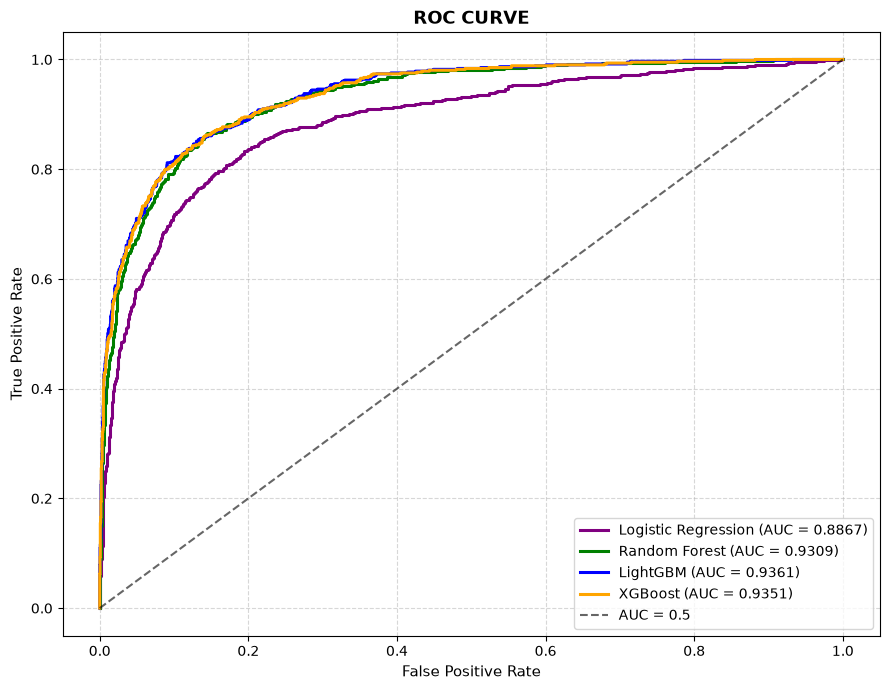

In [42]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 7))

# Bảng màu cho từng đường vẽ
colors = {
    'Logistic Regression': 'Purple', 
    'Random Forest': 'Green',    
    'LightGBM': 'Blue',           
    'XGBoost': 'Orange'             
}

# Vẽ đường ROC cho từng mô hình
for name, y_proba in probas_val.items():
    fpr, tpr, _ = roc_curve(y_val, y_proba)
    auc_val = roc_auc_score(y_val, y_proba)
    
    plt.plot(
        fpr, 
        tpr, 
        label=f"{name} (AUC = {auc_val:.4f})", 
        color=colors.get(name, None),
        linewidth=2.2
    )

# Đường chéo tham chiếu
plt.plot([0, 1], [0, 1], 'k--', label='AUC = 0.5', alpha=0.6)

# Giao diện biểu đồ
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.title('ROC CURVE', fontsize=13, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

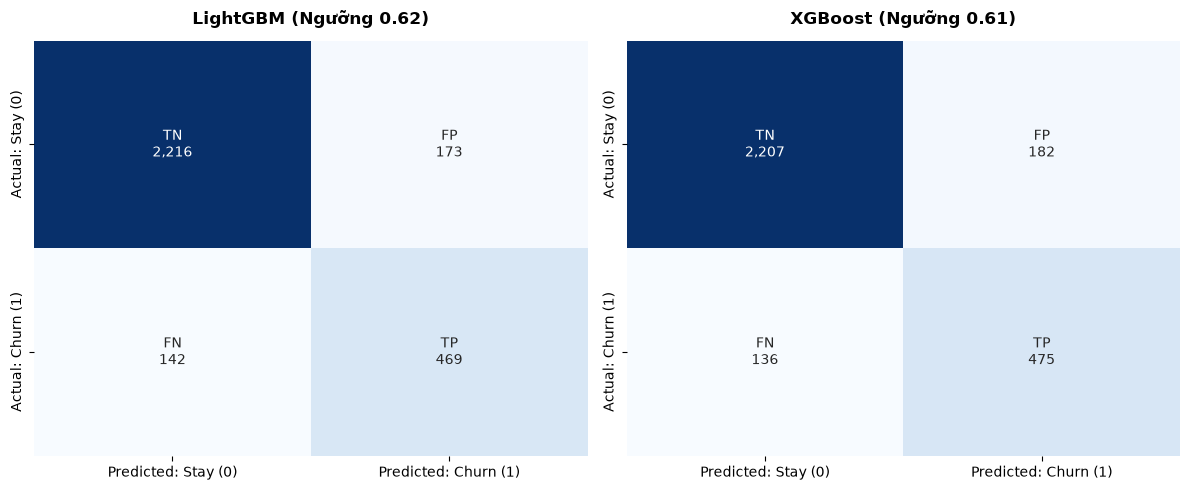

In [44]:
# 1. Dự đoán theo ngưỡng cắt cho từng mô hình
pred_lgb_062 = (probas_val['LightGBM'] >= 0.62).astype(int)
pred_xgb_061 = (probas_val['XGBoost'] >= 0.61).astype(int)

# Gom thông tin vào dictionary để duyệt vẽ đồ thị
models_cm = {
    'LightGBM (Ngưỡng 0.62)': pred_lgb_062,
    'XGBoost (Ngưỡng 0.61)': pred_xgb_061
}

cell_meanings = ["TN", "FP", "FN", "TP"]

# 2. Tạo khung vẽ gồm 1 hàng x 2 cột
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

for idx, (title, pred) in enumerate(models_cm.items()):
    # Tính ma trận nhầm lẫn
    cm = confusion_matrix(y_val, pred)
    
    # Gán nhãn kèm số lượng theo cm
    formatted_labels = [
        f"{meaning}\n{count:,}" 
        for meaning, count in zip(cell_meanings, cm.flatten())
    ]
    formatted_labels = np.array(formatted_labels).reshape(2, 2)
    
    # Vẽ Heatmap lên từng subplot
    sns.heatmap(
        cm, 
        annot=formatted_labels, 
        fmt='', 
        cmap='Blues', 
        cbar=False,
        ax=axes[idx],
        xticklabels=['Predicted: Stay (0)', 'Predicted: Churn (1)'],
        yticklabels=['Actual: Stay (0)', 'Actual: Churn (1)']
    )
    axes[idx].set_title(title, fontsize=12, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

**ĐÁNH GIÁ**

Sau khi thử nghiệm nhiều thuật toán với các kỹ thuật xử lý dữ liệu mất cân bằng (class_weight cho LightGBM, Random Forest và scale_pos_weight cho XGBoost), kết quả trên tập Validation cho thấy hai mô hình LightGBM và XGBoost đem lại hiệu năng vượt trội gần như tương đương nhau.

Tuy nhiên, lựa chọn LightGBM làm mô hình cốt lõi cuối cùng cho dự án này, với ngưỡng cắt 0.5. Lý do là vì:
* Ở cùng một mức hiệu năng toán học, LightGBM tối ưu hơn XGBoost rất nhiều về tốc độ huấn luyện và tài nguyên bộ nhớ. Điều này cực kỳ quan trọng với ngân hàng khi hệ thống phải xử lý dữ liệu hàng triệu khách hàng hàng ngày.
* Về mặt lý thuyết, LightGBM đạt F1-Score tốt nhất ở ngưỡng 0.62 (FN = 142, FP = 173). Tuy nhiên, dưới góc độ nghiệp vụ Ngân hàng (Bank Churn), chi phí bỏ sót một khách hàng rời đi (False Negative - FN) thường lớn hơn nhiều so với chi phí chăm sóc nhầm khách hàng trung thành (False Positive - FP).

=> Do đó, quyết định chọn **mô hình LightGBM với ngưỡng cắt (threshold) là 0.5** (FN = 99, FP = 290) để áp dụng lên tập Test và hệ thống thực tế. Lựa chọn này giúp ngân hàng giữ chân thêm được 43 khách hàng thực sự sắp rời đi so với ngưỡng 0.62, tối đa hóa lợi nhuận và giảm thiểu thiệt hại tài chính tổng thể cho ngân hàng.

### Model Explainability | Giải thích mô hình LightGBM bằng SHAP

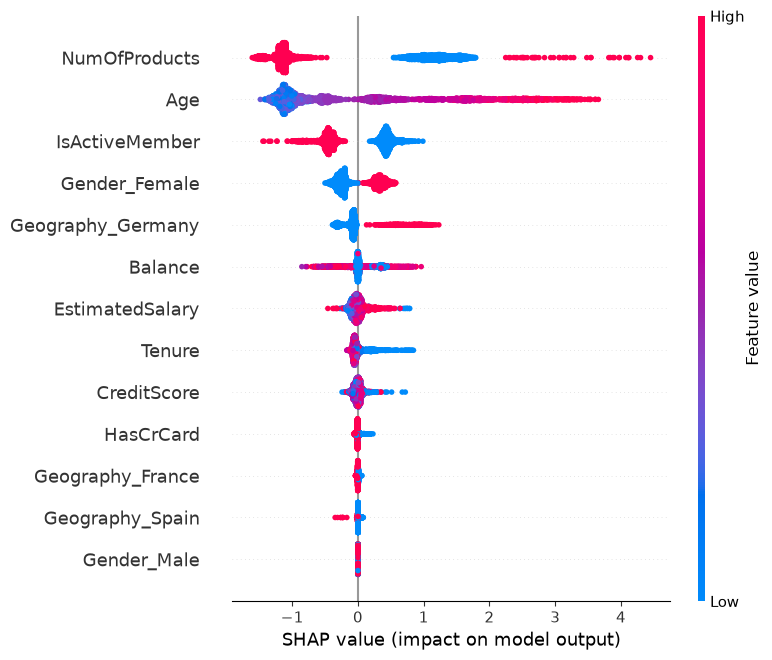

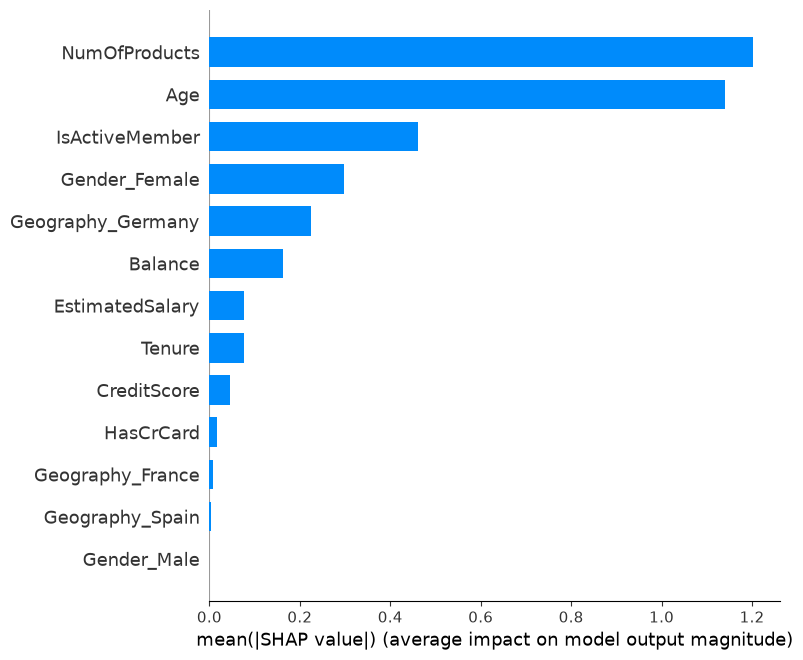

In [48]:
import shap

# Lấy mô hình LightGBM đã train
lgb_model = trained_models['LightGBM']

# Khởi tạo TreeExplainer cho LightGBM
explainer = shap.TreeExplainer(lgb_model)

# Tính SHAP values trên tập validation
shap_values = explainer.shap_values(X_val_final)

# Với bài toán phân loại nhị phân, lấy SHAP values của class 1 (Exited = 1)
# Nếu shap_values trả về dạng list [class 0, class 1]
if isinstance(shap_values, list):
    shap_vals = shap_values[1]
else:
    shap_vals = shap_values

# Trực quan hóa mức độ quan trọng và chiều tác động của các biến
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals, X_val_final, show=True)

# Trực quan hóa dạng cột mức độ quan trọng trung bình
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals, X_val_final, plot_type="bar", show=True)

In [46]:
# Dự đoán xác suất nhãn 1 (churn) trên tập test đã qua tiền xử lý
test_proba = lgb_model.predict_proba(X_test_final)[:, 1]

# Tạo DataFrame kết quả với 2 cột id và churn_proba
df_submission = pd.DataFrame({
    'id': test_ids,
    'churn_proba': test_proba
})

# Xuất ra file csv
df_submission.to_csv("bank_churn_prediction.csv", index=False)

print("Đã xuất file bank_churn_prediction.csv thành công!")
print(df_submission.head())

Đã xuất file bank_churn_prediction.csv thành công!
      id  churn_proba
0  15000     0.552557
1  15001     0.123183
2  15002     0.918203
3  15003     0.207316
4  15004     0.224081


In [47]:
import joblib
# Lưu các đối tượng vào ổ đĩa
joblib.dump(lgb_model, 'best_lightgbm_model.pkl')
joblib.dump(encoder, 'onehot_encoder.pkl')
joblib.dump(scaler, 'standard_scaler.pkl')
print("Đã lưu mô hình và bộ tiền xử lý thành công!")

Đã lưu mô hình và bộ tiền xử lý thành công!
